**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**01 | MPIIGaze Source Audit and Participant-Level Protocol**

![MPIIGaze source archive, file inventory, MATLAB metadata and proposed participant-held-out protocol](../../images/01_mpiigaze_source_audit_and_protocol.svg)

**Objective:** Establish original MPIIGaze source provenance, participant availability, MATLAB container structure and proposed independent-person evaluation before any image-based model is trained.

**Dataset:** [Official MPIIGaze](https://www.collaborative-ai.org/research/datasets/MPIIGaze/) / [DaRUS v1 archive](https://doi.org/10.18419/darus-3230). The publisher reports 15 participants and 213,659 collected images; these are **not observed counts produced by this notebook**.

**Notebook scope:** Colab setup, explicit original-data access, source inventory, participant/day support, MATLAB header inspection, publisher evaluation lists, proposed evaluation protocol, a source evidence figure and a downloadable output ZIP.

**Limit:** Notebook 01 does not fit models or claim verified 3D target correspondence. Notebook 02 establishes the sample index, gaze frame and participant-level outer folds.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import json
import shutil
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 5. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from mpiigaze_io import (
    SOURCE_PAGE, SOURCE_DOI, ensure_mpiigaze_source,
    source_inventory, participant_source_support, inspect_mat_header,
)

# ------------------------ 6. Output and Source Paths -------------------------
study = root / "vision_based_gaze_estimation"
output_dir = study / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "mpiigaze"
raw_dir.parent.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", output_dir)
print("Source directory:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(shutil.disk_usage(raw_dir.parent).free / 2**30, 2))


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Python: 3.13.18
Free disk (GiB): 107.39


**02. Locate or Acquire the MPIIGaze Source**

The official archive is approximately 2.1–2.2 GB and is available for non-commercial scientific research. All acquisition and extraction take place in the remote Colab runtime, even when the notebook is opened in VS Code. Existing extracted participant/day MAT containers are reused; otherwise, the source adapter extracts an existing runtime archive or automatically downloads from the publisher, with the official DaRUS archive as a fallback.

The raw data stay in the ignored runtime `data/raw/mpiigaze/` directory. Only stage-owned analysis files are packaged for manual download. If acquisition fails, execution stops with the actual source error rather than silently skipping the analysis.

In [3]:
# ==================== 02. Locate Official MPIIGaze Source ====================

# --------------------- 1. Acquire or Reuse Original Data ---------------------
raw_dir = ensure_mpiigaze_source(raw_dir)
source_available = True

# ------------------------- 2. Report Runtime Source --------------------------
print("Original MATLAB source available:", source_available)
print("Source directory:", raw_dir)
print("Official source:", SOURCE_PAGE)
print("Archive reference:", SOURCE_DOI)

Retrieving official MPIIGaze archive: https://collaborative-ai.org/files/datasets/MPIIGaze.tar.gz
Source acquisition attempt failed: MPIIGaze.tar.gz: HTTPError: HTTP Error 404: Not Found
Retrieving official MPIIGaze archive: https://darus.uni-stuttgart.de/api/access/datafile/:persistentId?persistentId=doi:10.18419/DARUS-3230/1
Downloaded 256 MiB
Downloaded 512 MiB
Downloaded 768 MiB
Downloaded 1,024 MiB
Downloaded 1,280 MiB
Downloaded 1,536 MiB
Downloaded 1,792 MiB
Downloaded 2,048 MiB
Archive received: 2.16 GiB
Extracting original MPIIGaze files in the runtime...
Source available: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Normalised MAT containers: 1,042
Original MATLAB source available: True
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Official source: https://www.collaborative-ai.org/research/datasets/MPIIGaze/
Archive reference: https://doi.org/10.18419/darus-3230


**03. Audit Original Source Files**

Identify the publisher's `Original`, `Normalized`, `Calibration`, `Evaluation Subset` and `Annotation Subset` components. An indexed file is **not necessarily one image**; the MAT format can contain many records.

In [4]:
# =================== 03. Audit Source Files and Provenance ===================

# ---------------------- 1. Build the Observed Inventory ----------------------
if source_available:
    inventory = source_inventory(raw_dir)
    if inventory.empty or inventory.relative_path.duplicated().any():
        raise ValueError("Source files missing or duplicated")
    if not inventory.component.eq("Normalized").any():
        raise ValueError(
            "The extracted dataset lacks the Normalized component; "
            "inspect archive paths before continuing."
        )
    inventory.to_csv(output_dir / "01_file_inventory.csv", index=False)
    print("Observed source files:", len(inventory))
    display(inventory.groupby("component").agg(
        files=("relative_path", "size"),
        megabytes=("size_bytes", lambda x: round(x.sum() / 2**20, 1)),
    ).reset_index())
    display(inventory.head(12))
else:
    print("Source audit skipped: official files not yet available.")

Observed source files: 430180


,component,files,megabytes
0,Annotation Subset,31,0.8
1,Evaluation Subset,67,3.2
2,Normalized,1057,834.9
3,Original,429011,4135.9
4,Other,14,0.0


,relative_path,component,participant_id,recording_day,suffix,size_bytes
0,MPIIGaze/.DS_Store,Other,None,None,,6148
1,MPIIGaze/6 points-based face model.mat,Other,None,None,.mat,336
2,MPIIGaze/Annotation Subset/p00.txt,Annotation Subset,None,None,.txt,68493
3,MPIIGaze/Annotation Subset/p01.txt,Annotation Subset,None,None,.txt,67941
4,MPIIGaze/Annotation Subset/p02.txt,Annotation Subset,None,None,.txt,82160
5,MPIIGaze/Annotation Subset/p03.txt,Annotation Subset,None,None,.txt,50481
6,MPIIGaze/Annotation Subset/p04.txt,Annotation Subset,None,None,.txt,68888
7,MPIIGaze/Annotation Subset/p05.txt,Annotation Subset,None,None,.txt,74260
8,MPIIGaze/Annotation Subset/p06.txt,Annotation Subset,None,None,.txt,70389
9,MPIIGaze/Annotation Subset/p07.txt,Annotation Subset,None,None,.txt,60988


**04. Audit Participant and Day Support**

Extract original participant folder identifiers and distinguish actual normalised MATLAB containers from source image samples. The present source archive must determine the participant list, not a fixed count copied from a paper.

In [5]:
# =================== 04. Audit Participant and Day Support ===================

# ----------------- 1. Check Participant Source Availability ------------------
if source_available:
    support = participant_source_support(inventory)
    if support.empty or support.participant_id.duplicated().any():
        raise ValueError(
            "No participant folder identifiers found, e.g. p00")
    support.to_csv(output_dir / "01_participant_support.csv", index=False)
    display(support)
    print("Participants represented in source:", len(support))
    missing_normalised = support.loc[
        support.normalised_mat_files.eq(0), "participant_id"].tolist()
    if missing_normalised:
        print("No normalised MAT files for:", missing_normalised)
else:
    print("Participant support requires original MPIIGaze files.")

,participant_id,source_files,normalised_mat_files,original_files,calibration_files,observed_day_folders
0,p00,60126,78,60048,0,39
1,p01,48638,138,48500,0,69
2,p02,56242,78,56164,0,39
3,p03,70484,130,70354,0,65
4,p04,33796,50,33746,0,25
5,p05,33351,76,33275,0,38
6,p06,37213,124,37089,0,62
7,p07,31305,112,31193,0,56
8,p08,21644,94,21550,0,47
9,p09,16099,40,16059,0,20


Participants represented in source: 15


**05. Inspect Normalised MATLAB Schemas**

Read a bounded representative MAT header for each observed participant, listing variable names, shapes and storage types. This is **not** evidence that the label vectors or image-index correspondence have already been validated.

In [6]:
# =================== 05. Inspect Normalised MATLAB Schemas ===================

# ------------------ 1. Select One Container per Participant ------------------
if source_available:
    normalized = inventory.loc[
        inventory.component.eq("Normalized")
        & inventory.suffix.eq(".mat")
        & inventory.participant_id.notna()
    ].sort_values(["participant_id", "relative_path"])
    representatives = normalized.drop_duplicates("participant_id")
    if representatives.empty:
        raise ValueError("No normalised MATLAB containers are available")
    schema_rows = []
    for item in representatives.itertuples(index=False):
        for variable in inspect_mat_header(raw_dir / item.relative_path):
            schema_rows.append({
                "participant_id": item.participant_id,
                "relative_path": item.relative_path, **variable
            })
    mat_schema = pd.DataFrame(schema_rows)
    if mat_schema.empty:
        raise ValueError("No MATLAB header variables were found")
    mat_schema.to_csv(output_dir / "01_mat_schema.csv", index=False)
    print("MAT containers inspected:", len(representatives))
    display(mat_schema.head(30))
else:
    print("MATLAB header inspection requires the source archive.")

MAT containers inspected: 15


,participant_id,relative_path,variable,shape,storage_type,format
0,p00,MPIIGaze/Data/Normalized/p00/day01.mat,data,"(1, 1)",struct,MATLAB v5
1,p00,MPIIGaze/Data/Normalized/p00/day01.mat,filenames,"(995, 1)",cell,MATLAB v5
2,p01,MPIIGaze/Data/Normalized/p01/day01.mat,data,"(1, 1)",struct,MATLAB v5
3,p01,MPIIGaze/Data/Normalized/p01/day01.mat,filenames,"(510, 1)",cell,MATLAB v5
4,p02,MPIIGaze/Data/Normalized/p02/day01.mat,data,"(1, 1)",struct,MATLAB v5
5,p02,MPIIGaze/Data/Normalized/p02/day01.mat,filenames,"(307, 1)",cell,MATLAB v5
6,p03,MPIIGaze/Data/Normalized/p03/day01.mat,data,"(1, 1)",struct,MATLAB v5
7,p03,MPIIGaze/Data/Normalized/p03/day01.mat,filenames,"(217, 1)",cell,MATLAB v5
8,p04,MPIIGaze/Data/Normalized/p04/day01.mat,data,"(1, 1)",struct,MATLAB v5
9,p04,MPIIGaze/Data/Normalized/p04/day01.mat,filenames,"(1017, 1)",cell,MATLAB v5


**06. Inspect Evaluation and Annotation Lists**

List source-defined evaluation and landmark-annotation files without equating non-empty text lines with valid image examples. The publisher's documentation contains an annotated-subset-count discrepancy that must be checked against the chosen release.

In [7]:
# ================ 06. Examine Evaluation and Annotation Lists ================

# -------------------- 1. Identify Publisher Sample Lists ---------------------
if source_available:
    list_files = inventory.loc[
        inventory.component.isin(
            ["Evaluation Subset", "Annotation Subset"])
        & inventory.suffix.isin([".txt", ".csv", ".list"])
    ]
    list_rows = []
    for item in list_files.itertuples(index=False):
        with (raw_dir / item.relative_path).open(
                encoding="utf-8", errors="replace") as handle:
            count = sum(bool(line.strip()) for line in handle)
        list_rows.append({
            "relative_path": item.relative_path,
            "component": item.component,
            "nonempty_text_lines": count,
        })
    lists = pd.DataFrame(list_rows, columns=[
        "relative_path", "component", "nonempty_text_lines"])
    lists.to_csv(
        output_dir / "01_evaluation_list_inventory.csv", index=False)
    display(lists.head(30))
    print("Publisher lists observed:", len(lists))
    print("Text-line counts are NOT verified 3D gaze sample counts.")
else:
    print("Evaluation list inspection requires original MPIIGaze files.")

,relative_path,component,nonempty_text_lines
0,MPIIGaze/Annotation Subset/p00.txt,Annotation Subset,867
1,MPIIGaze/Annotation Subset/p01.txt,Annotation Subset,860
2,MPIIGaze/Annotation Subset/p02.txt,Annotation Subset,1040
3,MPIIGaze/Annotation Subset/p03.txt,Annotation Subset,639
4,MPIIGaze/Annotation Subset/p04.txt,Annotation Subset,872
5,MPIIGaze/Annotation Subset/p05.txt,Annotation Subset,940
6,MPIIGaze/Annotation Subset/p06.txt,Annotation Subset,891
7,MPIIGaze/Annotation Subset/p07.txt,Annotation Subset,772
8,MPIIGaze/Annotation Subset/p08.txt,Annotation Subset,228
9,MPIIGaze/Annotation Subset/p09.txt,Annotation Subset,556


Publisher lists observed: 92
Text-line counts are NOT verified 3D gaze sample counts.


**07. Record a Participant-Level Protocol**

Document the observed participant IDs and the proposed Leave-One-Person-Out outer evaluation with participant-disjoint inner model selection. No Train/Validation/Test assignment is falsely asserted before verifying image–target correspondence in Notebook 02.

In [8]:
# =================== 07. Record Participant-Level Protocol ===================

# ---------------- 1. Save Source-Grounded Proposed Evaluation ----------------
if source_available:
    ids = support.loc[
        support.normalised_mat_files.gt(0), "participant_id"
    ].astype(str).tolist()
    if not ids:
        raise ValueError("No source participants with normalised MAT files")
    protocol = {
        "dataset": "MPIIGaze",
        "source_url": SOURCE_PAGE,
        "dataset_doi": SOURCE_DOI,
        "observed_participants": ids,
        "observed_source_files": int(len(inventory)),
        "sample_label_correspondence_verified": False,
        "camera_normalised_gaze_frame_verified": False,
        "model_ready": False,
        "proposed_outer_protocol": "participant-disjoint LOPO",
        "proposed_inner_protocol": "participant-disjoint validation",
        "proposed_primary_metric": "3D angular error in degrees",
        "sample_and_fold_assignment_producer": "Notebook 02",
    }
    (output_dir / "01_protocol.json").write_text(
        json.dumps(protocol, indent=2), encoding="utf-8")
    print("Source-grounded proposed protocol saved.")
    print("Sample-target geometry and folds remain Notebook 02 tasks.")
else:
    print("No source protocol saved without actual source inspection.")

Source-grounded proposed protocol saved.
Sample-target geometry and folds remain Notebook 02 tasks.


**08. Plot Source Inventory**

Visualise file counts by publisher component. These are **source-file counts**, not verified image totals, gaze-vector samples or evaluation scores.

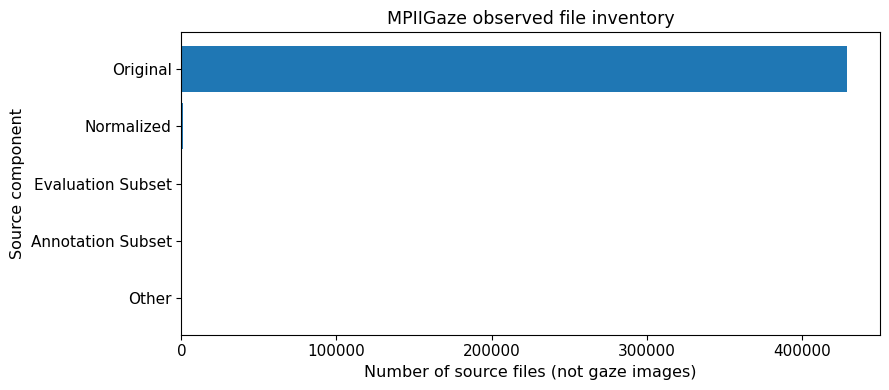

Source inventory figure saved.


In [9]:
# ==================== 08. Plot Observed Source Inventory =====================

# ------------------------ 1. Source Component Figure -------------------------
if source_available:
    counts = inventory.component.value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(counts.index, counts.values)
    ax.set(
        xlabel="Number of source files (not gaze images)",
        ylabel="Source component",
        title="MPIIGaze observed file inventory")
    fig.tight_layout()
    save_figure(fig, output_dir / "01_source_inventory.png")
    plt.show()
    print("Source inventory figure saved.")
else:
    print("No source figure produced without observed file counts.")

**09. Interpretation and Next Dependency**

Finish with the real observed file/participant counts, scope limitations and stage-owned output ZIP. The ZIP contains **only derived source metadata and figures**, not original participant images.

**Next:** Notebook 02 must validate original image/target joins, 3D coordinate conventions and actual participant-held-out Fold identities before any gaze model training.

In [10]:
# ================= 09. Interpret Source Evidence and Export ==================

# --------------------- 1. Report Observed Source Support ---------------------
if source_available:
    print("Observed source participants:", len(support))
    print("MATLAB header variables:", len(mat_schema))
    print("Publisher evaluation-list files:", len(lists))
    print("No image-level 3D target mapping or model fitting claimed.")
    required = (
        "01_file_inventory.csv", "01_participant_support.csv",
        "01_mat_schema.csv", "01_evaluation_list_inventory.csv",
        "01_protocol.json", "01_source_inventory.png",
    )
    missing = [name for name in required
               if not (output_dir / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Stage-01 outputs incomplete: {missing}")
    download_outputs_from_colab("vision_based_gaze_estimation/output", "01")
else:
    print("Environment setup finished; source dataset still absent.")
    print("No research results or source-derived files were fabricated.")
    print("Acquire the official dataset and rerun Sections 02–09.")

Observed source participants: 15
MATLAB header variables: 30
Publisher evaluation-list files: 92
No image-level 3D target mapping or model fitting claimed.
------------------------------------------------------------------------
Notebook 01
Files packaged: 6
  + 01_evaluation_list_inventory.csv
  + 01_file_inventory.csv
  + 01_mat_schema.csv
  + 01_participant_support.csv
  + 01_protocol.json
  + 01_source_inventory.png
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_01_Outputs.zip
